Adapted from: https://www.kaggle.com/tanlikesmath/rcic-fastai-starter

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# imports
import numpy as np
import pandas as pd
from fastai.vision import *
import torchvision
from torchvision import models, transforms as T

In [ ]:
data_dir = '/content/drive/My Drive/rxrx1/'

test_df = pd.read_csv(data_dir + "test.csv")
# print("Shape of test_data:", test_data.shape) #commented out as test_data is not defined yet
test_df.head()
train_df = pd.read_csv(data_dir + "train.csv")
# print("Shape of train_data:", train_data.shape) #commented out as train_data is not defined yet
train_df.head()



,id_code,experiment,plate,well,sirna
0,HEPG2-01_1_B03,HEPG2-01,1,B03,sirna_250
1,HEPG2-01_1_B04,HEPG2-01,1,B04,sirna_62
2,HEPG2-01_1_B05,HEPG2-01,1,B05,sirna_1115
3,HEPG2-01_1_B06,HEPG2-01,1,B06,sirna_602
4,HEPG2-01_1_B07,HEPG2-01,1,B07,sirna_529


In [ ]:
def generate_df(train_df,sample_num=1):
  """"
  Generates dataframe consisting of paths to images
  """
  train_df['path'] = train_df['experiment'].str.cat(train_df['plate'].astype(str).str.cat(train_df['well'],sep='/'),sep='/Plate') + '_s'+str(sample_num) + '_w'
  train_df = train_df.drop(columns=['id_code','experiment','plate','well']).reindex(columns=['path','sirna'])
  return train_df
proc_train_df = generate_df(train_df)

In [ ]:
proc_train_df.head(10)

,path,sirna
0,HEPG2-01/Plate1/B03_s1_w,sirna_250
1,HEPG2-01/Plate1/B04_s1_w,sirna_62
2,HEPG2-01/Plate1/B05_s1_w,sirna_1115
3,HEPG2-01/Plate1/B06_s1_w,sirna_602
4,HEPG2-01/Plate1/B07_s1_w,sirna_529
5,HEPG2-01/Plate1/B08_s1_w,sirna_863
6,HEPG2-01/Plate1/B09_s1_w,sirna_334
7,HEPG2-01/Plate1/B10_s1_w,sirna_1104
8,HEPG2-01/Plate1/B11_s1_w,sirna_153
9,HEPG2-01/Plate1/B12_s1_w,sirna_372


looking at example image:

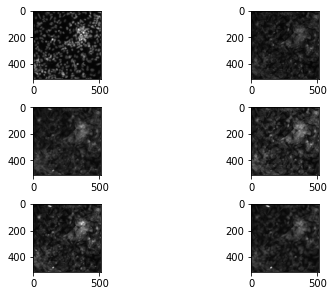

In [ ]:
import cv2
import matplotlib.pyplot as plt
image_datas = [0,0,0,0,0,0]
for i in [1,2,3,4,5,6]:
    image_datas[i-1] = cv2.imread(data_dir+"/train/HEPG2-01/Plate1/B03_s1_w{}.png".format(i))

f, axarr = plt.subplots(3,2, constrained_layout=True)
axarr[0][0].imshow(image_datas[0])
axarr[0][1].imshow(image_datas[1])

axarr[1][0].imshow(image_datas[2])
axarr[1][1].imshow(image_datas[3])

axarr[2][0].imshow(image_datas[4])
axarr[2][1].imshow(image_datas[5])


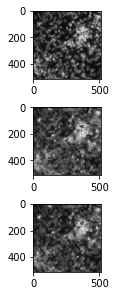

In [ ]:
f, axarr = plt.subplots(3,1, constrained_layout=True)
axarr[0].imshow(image_datas[0]+image_datas[1])
axarr[1].imshow(image_datas[2]+image_datas[3])
axarr[2].imshow(image_datas[4]+image_datas[5])

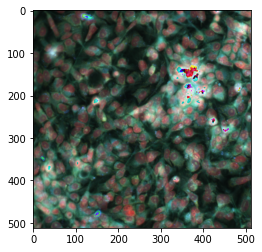

In [ ]:
dim1 = T.Compose([T.ToTensor()])((image_datas[0]+image_datas[1]))
dim2 = T.Compose([T.ToTensor()])((image_datas[2]+image_datas[3]))
dim3 = T.Compose([T.ToTensor()])((image_datas[4]+image_datas[5]))

[d11, d12, d13] = dim1; [d21, d22, d23] = dim2; [d31, d32, d33] = dim3


dims = [d11, d22, d33]
torchdims = [torch.from_numpy(np.expand_dims(dimm.numpy(), axis=0)) for dimm in dims]
merged_imgs = torch.cat(torchdims, dim=0)
plt.imshow(merged_imgs.permute(1, 2, 0)  )

Opening images:

In [ ]:
def open_rcic_image(fn):
    images = []
    for i in range(6):
        file_name = fn+str(i+1)+'.png'
        im = cv2.imread(file_name)
        im = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
        images.append(im)
    image = np.dstack(images)
    # print(pil2tensor(image, np.float32).shape)#.div_(255).shape)
    return Image(pil2tensor(image, np.float32).div_(255))

class MultiChannelImageList(ImageList):
    def open(self, fn):
        return open_rcic_image(fn)

# class MultiChannelImageList():
#     def open(self, fn):
#         return open_rcic_image(fn)

In [ ]:
il = MultiChannelImageList.from_df(df=proc_train_df,path=data_dir+'/train/')

In [ ]:
# function -> datatype means function returns variable of specified datatype
def image2np(image:Tensor)->np.ndarray:
    "Convert from torch style `image` to numpy/matplotlib style."
    res = image.cpu().permute(1,2,0).numpy()
    if res.shape[2]==1:
        return res[...,0]
    elif res.shape[2]>3:
        #print(res.shape)
        #print(res[...,:3].shape)
        return res[...,:3]
    else:
        return res

vision.image.image2np = image2np

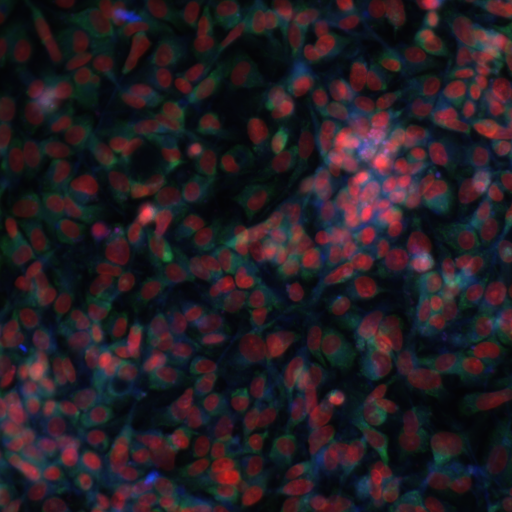

In [ ]:
il[0]

With the multi-channel ImageList defined, we can now create a DataBunch of the train images. Let's first create a stratified split of dataset and get the indices.

In [ ]:
from sklearn.model_selection import StratifiedKFold
#train_idx, val_idx = next(iter(StratifiedKFold(n_splits=int(1/0.035),random_state=42).split(proc_train_df, proc_train_df.sirna)))
from sklearn.model_selection import train_test_split
train_df,val_df = train_test_split(proc_train_df,test_size=0.035, stratify = proc_train_df.sirna, random_state=42)
_proc_train_df = pd.concat([train_df,val_df])

Now we create the DataBunch

In [ ]:
data = (MultiChannelImageList.from_df(df=_proc_train_df,path=data_dir+'/train/')
        .split_by_idx(list(range(len(train_df),len(_proc_train_df))))
        .label_from_df()
        .transform(get_transforms(),size=256)
        .databunch(bs=128,num_workers=4)
        .normalize()
       )

/usr/local/lib/python3.7/dist-packages/fastai/basic_data.py:262: UserWarning: There seems to be something wrong with your dataset, for example, in the first batch can't access these elements in self.train_ds: 15812
  warn(warn_msg)


You can deactivate this warning by passing `no_check=True`.


In [ ]:
data.show_batch()